### Imports

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage

### Définitions

**CAH : classification ascendante hiérarchique**

**Principe** : autant de classes que d'individus (chaque individu forme un groupe), puis fusion des deux classes les plus proches, jusqu'à qu'il ne reste qu'un seul groupe.  
Résultat : arbre (dendogramme = historique des fusions) que l'on coupe à la hauteur voulue pour obtenir les classes.  

Ascendante car on part des individus pour remonter vers le groupe total & hiérarchique puisque chaque partition est emboîtée dans la suivante.

S'utilise sur des data de quelques milliers d'individus au max. et quand le nombre de classe est inconnu + besoin visualisation arbre.

*Dans ce notebook, exemple d'une enseigne qui suit deux indicateurs clientèle :*   
    - montant mensuel des achats  
    - nombre d'achats (par mois)

⇒ l'idée est de former des groupes de clients qui se ressemblent, tout en étant différents des autres groupes.
Une groupe se décrit en une phrase comme "petits paniers", "clients occasionnels", "clients fidèles".  
La CAH fusionne les observations les plus proches ; mais « proche » doit avoir un sens pour les variables étudiées

Cette classification est dite non-supervisée car tout repose sur une mesure de ressemblance, pas d'étiquette connue en avance.

#### Pourquoi plusieurs mesures de distance

1. Les variables peuvent être de natures différentes  
- Quantitative : une valeur numérique mesurable, comme l’âge, le revenu ou la taille.  
- Binaire : deux possibilités, comme oui/non ou présence/absence.  
- Qualitative : des catégories, comme une couleur, une région ou un métier.  
Certaines catégories ont un ordre (faible, moyen, élevé), d’autres non.  
- Mixte : un tableau qui combine plusieurs de ces types.

2. La mesure doit convenir à la nature des variables  
Pour des mesures numériques, on peut calculer un écart : entre 20 et 25 ans, la différence vaut 5. Mais soustraire « bleu » et « rouge » n’a pas de sens : ce sont des catégories, pas des nombres mesurables.  
On peut toutefois comparer des catégories autrement, par exemple en disant si deux individus ont la même couleur ou non. Si on transforme les couleurs en nombres (rouge = 1, bleu = 2…), cela ne rend pas la soustraction pertinente : le codage numérique est arbitraire.  

3. Même pour des nombres, plusieurs distances sont possibles  
Par exemple, entre ((0,0)) et ((3,4)) :  

- distance euclidienne : (5), comme une ligne droite, " à vol d'oiseau" ;
- distance euclidienne au carré : (25), fait augmenter d'avantage les grands écarts que les petits et donne donc plsu de poids aux observations éloignées ou atypiques = mesure d'écart et pas une distance au sens strict;
- distance Manhattan : (7), en additionnant les écarts sur chaque axe.  
*cf.* ci-dessous les mesures de distances.

Le choix dépend donc de ce que représentent les variables et de la notion de ressemblance que l’on veut mesurer. Pour des données mixtes, on peut calculer une dissimilarité qui combine des règles adaptées à chaque type de variable, plutôt que d’appliquer directement une distance euclidienne à tout le tableau.

#### Les différentes mesures de distance

##### Manhattan, Minkowshi et Chebyshev

Pour deux points $ (x=(x_1,\dots,x_n)) et (y=(y_1,\dots,y_n))$, chaque mesure combine les écarts entre leur cordonnées d'une manière différente.

- Manhattan : $d(x,y)=\sum_{k=1}^{n}|x_k-y_k|$  
Additionne les écarts absolus comme si on se déplaçait le long des axes avec angle droit ⇒ moins sensble à un grand écart isolé

- Minkowski : $d_p(x,y)=\left(\sum_{k=1}^{n}|x_k-y_k|^p\right)^{1/p}$  
où $\qquad p\geq 1$    
Formule générale qui permet de pondérer les écarts selon le paramètre (p)  
⇒ pour (p=1), on obtient Manhattan ; pour (p=2), la distance euclidienne  

- Chebyshev : $d(x,y)=\max_{1\leq k\leq n}|x_k-y_k|$  
Ne garde que le plus grand écart sur une coordonnée (la limite de Minkowski quand p devient très grand)

*ex : pour A(1, 2) et B(4, 6)*  
les écarts = 3 et 4  
Manhattan = 7  
Euclidienne = 5  
Chebyshev = 4

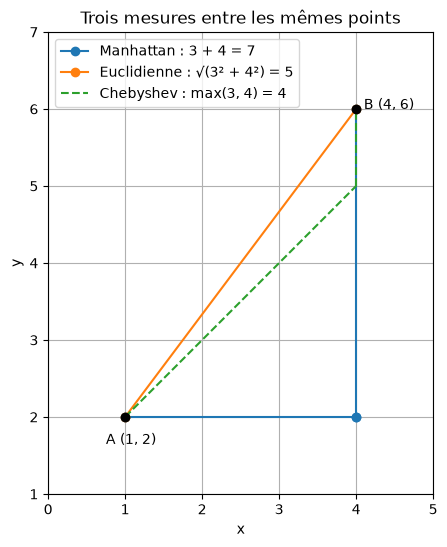

In [25]:
A = (1, 2)
B = (4, 6)

plt.figure(figsize=(7, 6))

# Manhattan : déplacements horizontaux puis verticaux
plt.plot([1, 4], [2, 2], "o-", color="tab:blue",
         label="Manhattan : 3 + 4 = 7")
plt.plot([4, 4], [2, 6], "o-", color="tab:blue")

# Euclidienne : ligne droite
plt.plot([1, 4], [2, 6], "o-", color="tab:orange",
         label="Euclidienne : √(3² + 4²) = 5")

# Chebyshev : déplacement diagonal, puis le reste
plt.plot([1, 4], [2, 5], "--", color="tab:green")
plt.plot([4, 4], [5, 6], "--", color="tab:green",
         label="Chebyshev : max(3, 4) = 4")

plt.scatter(*A, color="black", zorder=5)
plt.scatter(*B, color="black", zorder=5)
plt.text(A[0] - 0.25, A[1] - 0.35, "A (1, 2)")
plt.text(B[0] + 0.1, B[1], "B (4, 6)")

plt.xlim(0, 5)
plt.ylim(1, 7)
plt.xticks(range(0, 6))
plt.yticks(range(1, 8))
plt.grid(True)
plt.gca().set_aspect("equal", adjustable="box")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Trois mesures entre les mêmes points")
plt.legend()
plt.show()

##### La distance de Mahalanobis

$d_(x, y) = \sqrt{(x-y)^{\mathsf T} S^{-1}(x-y)}$

Mesure l’écart entre deux vecteurs (x) et (y) en tenant compte de la dispersion des variables et de leurs corrélations

$(x-y)$ est le vecteur des écarts entre les deux points  
$((x-y)^{\mathsf T})$ est ce vecteur écrit en ligne ⇒ le produit matriciel donne un nombre  
$(S)$ est la matrice de variance-covariance ⇒ $(S^{-1})$ est son inverse.   

Si les variables sont positivement corrélées, des points qui s’écartent ensemble dans la direction de cette corrélation sont assez habituels. Un point tout aussi éloigné, mais dans la direction opposée à cette tendance, est plus atypique et reçoit une plus grande distance de Mahalanobis.

Voici un exemple avec le centre 3,54  
Les points U et V sont à la même distance euclidienne du centre, mais U suit la direction de la corrélation et V va à contre-sens (est environ 3,5 fois plus éloigné de ce centre selon Mahalanobis que U) 

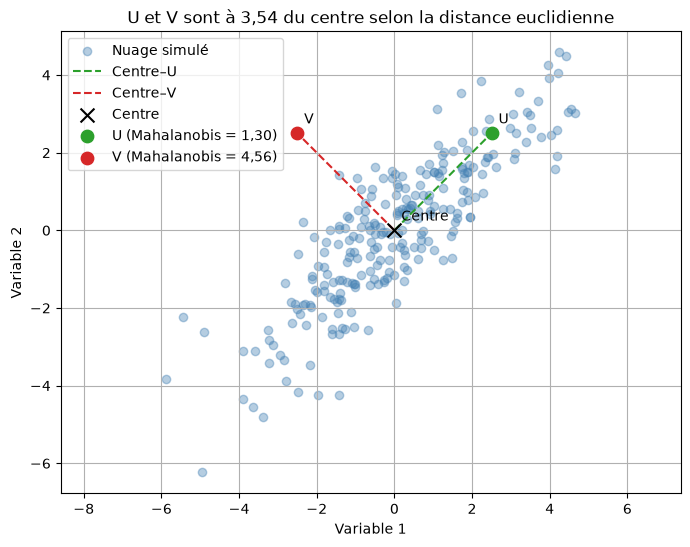

In [30]:
centre = np.array([0.0, 0.0])
rayon = 3.54
d_mahal_U = 1.30
d_mahal_V = 4.56

# U suit la corrélation positive ; V va à contre-sens.
direction_U = np.array([1.0, 1.0]) / np.sqrt(2)
direction_V = np.array([-1.0, 1.0]) / np.sqrt(2)

U = centre + rayon * direction_U
V = centre + rayon * direction_V

# Covariance illustrative, choisie pour obtenir les distances indiquées.
Q = np.column_stack((direction_U, direction_V))
S = Q @ np.diag([
    rayon**2 / d_mahal_U**2,
    rayon**2 / d_mahal_V**2
]) @ Q.T

# Nuage artificiel généré autour du centre selon cette covariance.
rng = np.random.default_rng(42)
nuage = rng.multivariate_normal(centre, S, size=250)

plt.figure(figsize=(8, 6))

plt.scatter(
    nuage[:, 0], nuage[:, 1],
    color="steelblue", alpha=0.4, label="Nuage simulé", zorder=1
)

plt.plot(
    [centre[0], U[0]], [centre[1], U[1]],
    "--", color="tab:green", label="Centre–U", zorder=2
)
plt.plot(
    [centre[0], V[0]], [centre[1], V[1]],
    "--", color="tab:red", label="Centre–V", zorder=2
)

plt.scatter(*centre, color="black", marker="x", s=100, label="Centre", zorder=3)
plt.scatter(*U, color="tab:green", s=80, label="U (Mahalanobis = 1,30)", zorder=3)
plt.scatter(*V, color="tab:red", s=80, label="V (Mahalanobis = 4,56)", zorder=3)

plt.annotate("U", U, xytext=(5, 7), textcoords="offset points")
plt.annotate("V", V, xytext=(5, 7), textcoords="offset points")
plt.annotate("Centre", centre, xytext=(5, 7), textcoords="offset points")

plt.title("U et V sont à 3,54 du centre selon la distance euclidienne")
plt.xlabel("Variable 1")
plt.ylabel("Variable 2")
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.show()

##### Comparer des individus quand les variables sont **qualitatives, mixtes ou binaires**

# Finir prendre note, slide 35 

**1. Hamming : compter les différences**  (compare des catégories variable par variable )  

Pour deux individus décrits par (p) variables **qualitatives**, la distance de Hamming compte les variables sur lesquelles ils diffèrent  
On peut la donner comme un nombre de différences, ou comme une proportion :  

$d(x, y) = \frac{1}{p}\sum_{k=1}^{p}\mathbf{1}(x_k\ne y_k)$  
Ici, $\mathbf{1}(x_k\ne y_k)$ vaut 1 si la condition est vraie, et 0 sinon  

$
x=(\text{rouge},\text{oui},\text{petit}),\qquad
y=(\text{bleu},\text{oui},\text{grand})
$

⇒ ils diffèrent de 2 variables sur 3, donc $d_{\text{Hamming}}=2/3$.  
C’est adapté à des catégories nominales ; cela ne tient pas compte d’un éventuel ordre entre elles.

**2. Jaccard : comparer les présences** (en ignorant les absences communes)  

La distance de Jaccard est surtout utilisée pour des variables **binaires** quand la présence d’une caractéristique importe plus que son absence : par exemple, maladies présentes ou mots contenus dans un document. 

***Ex. :***
- (a) : nombre de caractéristiques présentes chez les deux individus ;
- (b) : présentes chez (x), absentes chez (y) ;
- (c) : absentes chez (x), présentes chez (y)  

$d_{\text{Jaccard}}(x,y) = 1-\frac{a}{a+b+c} = \frac{b+c}{a+b+c}$  

(x)possède les caractéristiques ${A,C}$, et (y) les caractéristiques ({A,B}). Ils partagent (A), mais chacun a une caractéristique différente : (a=1, b=1, c=1). Donc (d_{\text{Jaccard}}=2/3).
ou  

- $(X\cap Y)$ désigne les éléments présents dans les deux ensembles ;
- $(X\cup Y)$ tous les éléments présents dans au moins un des deux

$d_{\text{Jaccard}}(X,Y) = 1-\frac{|X\cap Y|}{|X\cup Y|} =\frac{|X\cup Y|-|X\cap Y|}{|X\cup Y|}$  

si $X={A,C}$ et $Y={A,B}$ alors $X\cap Y={A}$ et $X\cup Y={A,B,C}$.  
La similarité de Jaccard vaut (1/3), donc la distance vaut : $d_{\text{Jaccard}}(X,Y)=1-\frac{1}{3}=\frac{2}{3}$

Les absences chez les deux individus ne sont pas comptées. C’est utile, par exemple, si deux personnes ne partagent pas une maladie : cette absence commune ne signifie pas nécessairement qu’elles se ressemblent beaucoup.

Exemple :

**3. Gower : combiner des types de variables différents** (dans une même mesure)

La distance de Gower est conçue pour les tableaux **mixtes** : par exemple, âge (quantitatif), couleur (qualitatif) et présence/absence d’un équipement (binaire).

$d_{\text{Gower}}(x,y)
\frac{\sum_{k=1}^{p} w_k,d_k(x,y)}
{\sum_{k=1}^{p} w_k}$

Chaque variable contribue avec une dissimilarité adaptée à sa nature. Par exemple :

quantitative : (\displaystyle d_k=\frac{|x_k-y_k|}{\max(x_k)-\min(x_k)}) ;
qualitative nominale : (d_k=0) si les valeurs sont identiques, sinon (1) ;
binaire : comparaison adaptée, éventuellement sans compter les absences communes.
Les poids (w_k) peuvent exclure une variable si l’une des valeurs est manquante ou si cette comparaison ne s’applique pas.

Exemple simplifié : âge, couleur et réponse oui/non. Si l’écart d’âge ramené à son étendue vaut (0{,}25), les couleurs diffèrent ((1)) et les réponses binaires sont identiques ((0)), alors, avec un poids égal pour chaque variable :
$d_{\text{Gower}}=\frac{0{,}25+1+0}{3}\approx 0{,}42$  

### Les méthodes

La distance entre deux individus est claire, on l'a calcule. Mais entre **deux groupes il faut une règle** = **méthode d'aggrégation**  

> la méthode d'aggrégation ne remplace pas la distance, elle s'appuie dessus pour comparer des groupes.  

*Quelle méthode ?*  

- les deux plus proches : **lien simple**  
- les deux plus éloignés : **lien complet**  
- moyenne des distances : **lien moyen**
- plsu faible hausse de l'inertie intra-classe : **Ward**

##### LIEN SIMPLE (single linkage)

$D(A, B) = min (d(i, j) : i ∈ A, j ∈ B)$ 

On retient la plus petite des distances croisées (plus petite distance entre un individu d'un groupe et un individu d'un autre (paire))  
⇒ deux groupes sont proches dès que deux de leurs individus le sont  

Avantage : on repère les groupes allongés    
Limites : effet de chaînage et sensible aux points intermédiaires, c'est à dire qu'une chaîne de points intermédiaires suffit à relier deux nuages distincts.  
Soit l'effet de chaînage, peut réunir des groupes allongés ou peu compacts, même si leurs extrémités sont éloignées

##### LIEN COMPLET (complete linkage)

$D(A, B) = max (d(i, j) : i ∈ A, j ∈ B)$ 

On retient la plus grande des distances croisées (distance des deux individus les plus éloignés)  
⇒ deux groupes sont proches seulement si leurs membres les plus éloignés le sont aussi 

Avantage : groupe compacts de diamètre limité  
Limites : sensible aux valeurs extrêmes, et tend à couper de grands groupes

##### LIEN MOYEN (average linkage)

$D(A, B) = [1 / (nA × nB)] × Σᵢ∈A Σⱼ∈B d(i, j)$ 

$nA$ et $nB$ : nombres d'indvidus des groupes A et B, leur produit renvoie donc le nombre de couples croisés.

On fait la moyenne de toutes les distances croisées
⇒ compromis entre lien simple et complet 

Limites : une distance moyenne est moins intuitive à interpréter

##### WARD

$Δ(A, B) = [nA × nB / (nA + nB)] × ‖gA − gB‖²$ 

$nA$ et $nB$ : effectif des groupes  
$gA$ et $gB$ : centresde gravité  
$‖gA − gB‖²$ : distance euclidienne au carré entre les centres  
$[nA × nB / (nA + nB)]$ : facteur qui pénalise la fusion de deux grands groupes éloignés 

Chaque groupe a un centre de gravité (la moyenne de ses membres)  
L'inertie dans une même classe mesure la dispersion des individus autour de leur centre et fusionner deux groupes augmente toujours cette inertie  
⇒ Ward fusionne les deux groupes dont la réunion augmente le moins l'inertie intra-classe, soit celle qui rend les groupes les moins dispersés possible  

$\Delta$ = coût de fusion VS pas directement une distance entre deux points   
/!\ SciPy utilise une autre échelle pour exprimer le coût de fusion et exprime la hauteur du dendogramme selon une autre convention  
$\text{hauteur} = \sqrt{2\Delta}$  
La fusion est donc affiché à cette $\text{hauteur}$
⇒ es hauteurs affichées changent, pas l'ordre des valeurs (même coût plus petit)  

Avantage : groupes homogènes  
Limites : distance euclidienne requise

### Construction d'une matrice des distances (euclidiennes)

#### Données d'exemple

>les variables :
>  
>individu = clients  
x = montant mensuel des achats (en dizaien de milliers)  
y = nombre d'achats par mois  

In [3]:
data = {
    "Individu": ["A", "B", "C", "D", "E", "F", "G", "H", "I", "J"],
    "x": [4, 1, 1, 10, 10, 6, 7, 13, 14, 16],
    "y": [3, 3, 4, 10, 8, 8, 9, 2, 6, 5]
}

df_base = pd.DataFrame(data).set_index("Individu")
display(df_base)

,x,y
Individu,,
A,4,3
B,1,3
C,1,4
D,10,10
E,10,8
F,6,8
G,7,9
H,13,2
I,14,6


#### Distances euclidiennes (Pythagore):  

$$d(A,B)=\sqrt{(x_A-x_B)^2+(y_A-y_B)^2}$$

(A, B sont les deux clients comparés)  

⇒ si la distance est petite, il y a une forte ressemblance et inversement.  

Attention, avec une distance euclidienne, au choix des variables et à leur échelle, si besoin il faut standardiser les variables, pour que l'une n'écrase pas l'autre.   
Par exemple, la standardisation centrée-réduite transforme chaque variable en lui donnant une moyenne de 0 et un écart-type de 1.  
(standardiser n’est pas toujours souhaitable, si une variable doit réellement avoir plus d’importance pour l’analyse, il peut être pertinent de lui donner davantage de poids.)

In [4]:
coordonnees = df_base[["x", "y"]].to_numpy()

distances = np.sqrt(
    ((coordonnees[:, None, :] - coordonnees[None, :, :]) ** 2).sum(axis=2)
)

print(distances)

[[ 0.          3.          3.16227766  9.21954446  7.81024968  5.38516481
   6.70820393  9.05538514 10.44030651 12.16552506]
 [ 3.          0.          1.         11.40175425 10.29563014  7.07106781
   8.48528137 12.04159458 13.34166406 15.13274595]
 [ 3.16227766  1.          0.         10.81665383  9.8488578   6.40312424
   7.81024968 12.16552506 13.15294644 15.03329638]
 [ 9.21954446 11.40175425 10.81665383  0.          2.          4.47213595
   3.16227766  8.54400375  5.65685425  7.81024968]
 [ 7.81024968 10.29563014  9.8488578   2.          0.          4.
   3.16227766  6.70820393  4.47213595  6.70820393]
 [ 5.38516481  7.07106781  6.40312424  4.47213595  4.          0.
   1.41421356  9.21954446  8.24621125 10.44030651]
 [ 6.70820393  8.48528137  7.81024968  3.16227766  3.16227766  1.41421356
   0.          9.21954446  7.61577311  9.8488578 ]
 [ 9.05538514 12.04159458 12.16552506  8.54400375  6.70820393  9.21954446
   9.21954446  0.          4.12310563  4.24264069]
 [10.44030651 13

#### Matrice symétrique des distances

Matrice symétrique + une diagonale (distance d’un individu à lui-même) = 0  
⇒ on en lit qu'un triangle (*cf* fonction numpy tril et triu (array, k-ieme diag) plus bas)

In [5]:
matrice_distances = pd.DataFrame(
    distances,
    index=df_base.index,
    columns=df_base.index
)

display(matrice_distances.round(2))

Individu,A,B,C,D,E,F,G,H,I,J
Individu,,,,,,,,,,
A,0.00,3.00,3.16,9.22,7.81,5.39,6.71,9.06,10.44,12.17
B,3.00,0.00,1.00,11.40,10.30,7.07,8.49,12.04,13.34,15.13
C,3.16,1.00,0.00,10.82,9.85,6.40,7.81,12.17,13.15,15.03
D,9.22,11.40,10.82,0.00,2.00,4.47,3.16,8.54,5.66,7.81
E,7.81,10.30,9.85,2.00,0.00,4.00,3.16,6.71,4.47,6.71
F,5.39,7.07,6.40,4.47,4.00,0.00,1.41,9.22,8.25,10.44
G,6.71,8.49,7.81,3.16,3.16,1.41,0.00,9.22,7.62,9.85
H,9.06,12.04,12.17,8.54,6.71,9.22,9.22,0.00,4.12,4.24
I,10.44,13.34,13.15,5.66,4.47,8.25,7.62,4.12,0.00,2.24


### Démonstration "à la mano" de la création des classes // avec lien simple

#### Identification individus les plus proches

##### Avec une boucle

In [12]:
avec_boucle = matrice_distances.to_numpy()

distance_min = float("inf")
i_min, j_min = None, None

for i in range(len(avec_boucle)): # parcourt les lignes
    for j in range(i + 1, len(avec_boucle)): # parcourt les colonnes à droite de la diagonale
        if avec_boucle[i, j] < distance_min:
            distance_min = avec_boucle[i, j] # maj minimum
            i_min, j_min = i, j # attribution positions à la paire

if i_min is None or j_min is None:
    raise ValueError("Il faut au moins deux individus pour comparer les distances.")

a = matrice_distances.index[i_min]
b = matrice_distances.columns[j_min]

print(f"Plus proches : {a} et {b}, distance = {distance_min:.2f}")

Plus proches : B et C, distance = 1.00


##### Avec la fonction numpy `triu` // explications

Renvoie une copie d'un tableau - seulement le triangle supérieur - et les éléments situés sous la k-ième diagonale sont remplacés par zéro (k = diagonale de départ).  
(Pour les tableaux avec ndim supérieur à 2, triu s'appliquera aux deux derniers axes.)

In [13]:
test = np.array([[1,2,3,10],[4,5,6,11],[7,8,9,13],[10,11,12,20]])

display(test)
display(np.triu(test, 0)) # garde le triangle supérieur AVEC la diagonale principale
display(np.triu(test, 1)) # garde le triangle supérieur SANS la diagonale principale
display(np.triu(test, -1)) # ou (test, 2) etc..

array([[ 1,  2,  3, 10],
       [ 4,  5,  6, 11],
       [ 7,  8,  9, 13],
       [10, 11, 12, 20]])

array([[ 1,  2,  3, 10],
       [ 0,  5,  6, 11],
       [ 0,  0,  9, 13],
       [ 0,  0,  0, 20]])

array([[ 0,  2,  3, 10],
       [ 0,  0,  6, 11],
       [ 0,  0,  0, 13],
       [ 0,  0,  0,  0]])

array([[ 1,  2,  3, 10],
       [ 4,  5,  6, 11],
       [ 0,  8,  9, 13],
       [ 0,  0, 12, 20]])

##### Avec la fonction numpy triu // application

In [14]:
valeurs = matrice_distances.to_numpy()

i, j = np.triu_indices_from(valeurs, k=1)  # une seule moitié // symétrie et sans la diagonale principale de 0
# renvoie deux listes d’indices : i pour les lignes, j pour les colonnes

min = np.argmin(valeurs[i, j])

a = matrice_distances.index[i[min]]
b = matrice_distances.columns[j[min]]

print(f"Plus proches : {a} et {b}, distance = {valeurs[i[min], j[min]]:.2f}")

Plus proches : B et C, distance = 1.00


#### Fusions successives et actualisation de la matrice avec les nouveaux groupes

##### "à la mano"

In [15]:
D = matrice_distances.copy()
ordre_individus = list(df_base.index)
groupes = {individu: [individu] for individu in ordre_individus}
# dico où chaque individu = son propre groupe

while len(D) > 1: # jusqu'à qu'il ne reste qu'un groupe
    distances = D.to_numpy()
    i, j = np.triu_indices_from(distances, k=1)
    distance_min = np.argmin(distances[i, j])

    a = D.index[i[distance_min]]
    b = D.columns[j[distance_min]]
    distance = distances[i[distance_min], j[distance_min]]

    paire = sorted(groupes[a] + groupes[b],
                     key=ordre_individus.index)
    nouveau_groupe = "".join(paire)

    print(f"Fusion : {a} et {b} à la distance {distance:.2f}")

    reste = [groupe for groupe in D.index if groupe not in (a, b)]
    # liste des groupes qui ne participent pas à la fusion
    nouvelles_distances = {
        groupe: np.minimum(D.loc[a, groupe], D.loc[b, groupe])
        for groupe in reste
    }

    D = D.drop(index=[a, b], columns=[a, b])
    # retire de la matrice lignes et col des 2 groupe fusionnés

    D.loc[nouveau_groupe, reste] = [
        nouvelles_distances[groupe] for groupe in reste
    ]
    # ajoute une ligne pour le nouveau groupe et y inscrit ses distances aux autres groupes

    D.loc[reste, nouveau_groupe] = [
        nouvelles_distances[groupe] for groupe in reste
    ] 
    # ajoute la colonne

    D.loc[nouveau_groupe, nouveau_groupe] = 0
    # mais bien à 0 la distance du groupe avec lui-même

    groupes[nouveau_groupe] = paire
    del groupes[a]
    del groupes[b]
    # Màj dico 

    print("Matrice actualisée :")
    display(D.round(2))

Fusion : B et C à la distance 1.00
Matrice actualisée :


Individu,A,D,E,F,G,H,I,J,BC
Individu,,,,,,,,,
A,0.00,9.22,7.81,5.39,6.71,9.06,10.44,12.17,3.00
D,9.22,0.00,2.00,4.47,3.16,8.54,5.66,7.81,10.82
E,7.81,2.00,0.00,4.00,3.16,6.71,4.47,6.71,9.85
F,5.39,4.47,4.00,0.00,1.41,9.22,8.25,10.44,6.40
G,6.71,3.16,3.16,1.41,0.00,9.22,7.62,9.85,7.81
H,9.06,8.54,6.71,9.22,9.22,0.00,4.12,4.24,12.04
I,10.44,5.66,4.47,8.25,7.62,4.12,0.00,2.24,13.15
J,12.17,7.81,6.71,10.44,9.85,4.24,2.24,0.00,15.03
BC,3.00,10.82,9.85,6.40,7.81,12.04,13.15,15.03,0.00


Fusion : F et G à la distance 1.41
Matrice actualisée :


Individu,A,D,E,H,I,J,BC,FG
Individu,,,,,,,,
A,0.00,9.22,7.81,9.06,10.44,12.17,3.00,5.39
D,9.22,0.00,2.00,8.54,5.66,7.81,10.82,3.16
E,7.81,2.00,0.00,6.71,4.47,6.71,9.85,3.16
H,9.06,8.54,6.71,0.00,4.12,4.24,12.04,9.22
I,10.44,5.66,4.47,4.12,0.00,2.24,13.15,7.62
J,12.17,7.81,6.71,4.24,2.24,0.00,15.03,9.85
BC,3.00,10.82,9.85,12.04,13.15,15.03,0.00,6.40
FG,5.39,3.16,3.16,9.22,7.62,9.85,6.40,0.00


Fusion : D et E à la distance 2.00
Matrice actualisée :


Individu,A,H,I,J,BC,FG,DE
Individu,,,,,,,
A,0.00,9.06,10.44,12.17,3.00,5.39,7.81
H,9.06,0.00,4.12,4.24,12.04,9.22,6.71
I,10.44,4.12,0.00,2.24,13.15,7.62,4.47
J,12.17,4.24,2.24,0.00,15.03,9.85,6.71
BC,3.00,12.04,13.15,15.03,0.00,6.40,9.85
FG,5.39,9.22,7.62,9.85,6.40,0.00,3.16
DE,7.81,6.71,4.47,6.71,9.85,3.16,0.00


... (8 outputs left out)

Fusion : DEFG et HIJ à la distance 4.47
Matrice actualisée :


Individu,ABC,DEFGHIJ
Individu,,
ABC,0.00,5.39
DEFGHIJ,5.39,0.00


Fusion : ABC et DEFGHIJ à la distance 5.39
Matrice actualisée :


Individu,ABCDEFGHIJ
Individu,
ABCDEFGHIJ,0.0


##### Avec la fonction `linkage` qui réalise la CAH à partir des coordonnées des individus

In [ ]:
Z = linkage(coordonnees, method="single", metric="euclidean")
# method="single" pour lien simple

display(Z)

array([[ 1.        ,  2.        ,  1.        ,  2.        ],
       [ 5.        ,  6.        ,  1.41421356,  2.        ],
       [ 3.        ,  4.        ,  2.        ,  2.        ],
       [ 8.        ,  9.        ,  2.23606798,  2.        ],
       [ 0.        , 10.        ,  3.        ,  3.        ],
       [11.        , 12.        ,  3.16227766,  4.        ],
       [ 7.        , 13.        ,  4.12310563,  3.        ],
       [15.        , 16.        ,  4.47213595,  7.        ],
       [14.        , 17.        ,  5.38516481, 10.        ]])

##### Contenu de Z (étapes de fusion de la CAH)

**Z = tableau des fusions successives**

- col. 1 et 2 : indices des deux individus = deviennent groupes, ici 0 à 9 pour 10 individus de départ en les groupes = 10, 11, ...  
- col. 3 : distance à laquelle ils fusionnent  
- col. 4 : nbre individu dans groupe obtenu  

⇒ se lit comme ceci :  
Ligne 0 : 1 et 2 fusionnent à la distance 1. Le groupe créé s’appelle 10 et contient 2 individus.  
Ligne 1 : 5 et 6 fusionnent à la distance 1,414. Le groupe créé s’appelle 11.  
Ligne 2 : 3 et 4 fusionnent à la distance 2. Le groupe créé s’appelle 12.  
Ligne 3 : 8 et 9 fusionnent à la distance 2,236. Le groupe créé s’appelle 13.  
Ligne 4 : l’individu 0 rejoint le groupe 10 — donc le groupe {1, 2} — à la distance 3. Le nouveau groupe contient 3 individus.  
Ligne 5 : les groupes 11 et 12 fusionnent : {5, 6} rejoint {3, 4}. Le nouveau groupe contient 4 individus.  
Ligne 6 : l’individu 7 rejoint le groupe 13, qui contient {8, 9}. Le nouveau groupe contient 3 individus.  
Ligne 7 : les groupes 15 et 16 fusionnent. Ils rassemblent {3, 4, 5, 6} et {7, 8, 9}, soit 7 individus.  
Ligne 8 : les groupes 14 et 17 fusionnent à la distance 5,385. C’est la fusion finale, qui rassemble les 10 individus.  

#### Dendogramme // Historique des fusions

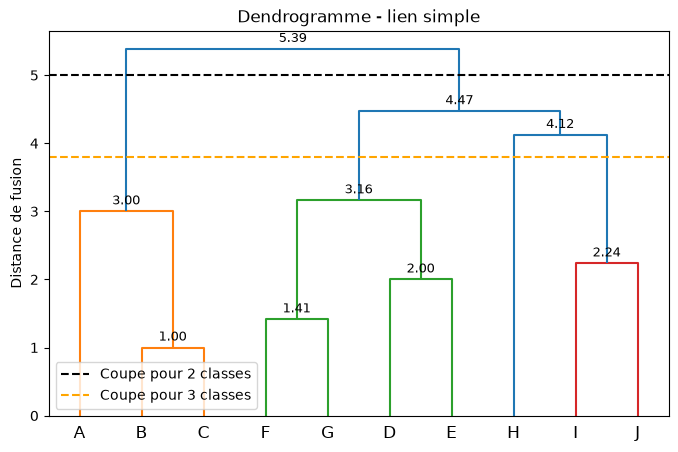

In [17]:
plt.figure(figsize=(8, 5))
resultat = dendrogram(Z, labels=df_base.index.tolist())

for x, y in zip(resultat["icoord"], resultat["dcoord"]):
    x_fusion = (x[1] + x[2]) / 2
    distance_fusion = y[1]
    plt.annotate(
        f"{distance_fusion:.2f}",
        (x_fusion, distance_fusion),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        fontsize=9
    )

plt.axhline(y=5, color="black", linestyle="--", label="Coupe pour 2 classes")
plt.axhline(y=3.8, color="orange", linestyle="--", label="Coupe pour 3 classes")
plt.ylabel("Distance de fusion")
plt.title("Dendrogramme - lien simple")
plt.legend()
plt.show()

In [24]:
classes = fcluster(Z, t=3, criterion="maxclust")
# t = nombre de classe voulues
# criterion="maxclust" indique que t correspond au nombre de classes, pas à une hauteur de distance

print(f"étiquette groupe : {classes}")
print("-" * 50)

for numero in sorted(set(classes)):
    membres = df_base.index[classes == numero].tolist()
    print(f"Classe {numero} : {membres}")
# boucle qui regroupe les individus portant la même étiquette

étiquette groupe : [1 1 1 2 2 2 2 3 3 3]
--------------------------------------------------
Classe 1 : ['A', 'B', 'C']
Classe 2 : ['D', 'E', 'F', 'G']
Classe 3 : ['H', 'I', 'J']


`fcluster` parcourt le tableau Z et découpe l’arbre hiérarchique pour attribuer une classe à chaque individu  
⇒  il renvoie un tableau avec un numéro de classe pour chaque individu  

classes contient ici : [1, 1, 1, 2, 2, 2, 2, 3, 3, 3], les étiquettes de groupes où chaque numéro correspond à une ligne des données avec le même ordre que les coordonnées (ici A à J)

### Méthode d'aggrégation : lien simple

### Méthode d'aggrégation : lien complet 

### Méthode d'aggrégation : lien moyen 

### Méthode d'aggrégation : Ward 